#Hybrid Bayesian-Neural Network Architecture for Cardiovascular Disease Prediction
## Course Title & code:Intelligent Systems EE8209
Project submitted by: Nashira Nasrudeen ,Indhu Ravichandran and Fiza Khan



## Project Overview

This notebook implements and compares three models for cardiovascular disease (CVD) prediction:

| Model | Description |
|-------|-------------|
| **Model A** | Gaussian Naive Bayes (Bayesian baseline) |
| **Model B** | Multilayer Perceptron (Neural baseline) |
| **Model C** | Hybrid GNB–MLP (proposed architecture) |

Evaluated across three publicly available datasets of different sizes and clinical contexts.

**Dataset Source:**
1. S. Ulianova, “Cardiovascular Disease dataset,” Kaggle, 2019.
[Online]. Available: https://www.kaggle.com/datasets/sulianova/
cardiovascular-disease-datase

 2. A. Bhardwaj, “Framingham heart study dataset,” Kaggle, 2022.
[Online]. Available: https://www.kaggle.com/datasets/aasheesh200/
framingham-heart-study-dataset

3. “Heart Failure Clinical Records Dataset,” Kaggle. [Online].
Available: https://www.kaggle.com/datasets/rithikkotha/
heart-failure-clinical-records-dataset



## 1. Imports & Configuration

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Dense, Dropout, Input, Concatenate
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam

# Reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Plot style
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['figure.dpi'] = 100
sns.set_style('whitegrid')

print("All imports successful.")
print(f"TensorFlow version: {tf.__version__}")


All imports successful.
TensorFlow version: 2.19.0


## 2. Data Loading & Exploration

### 2.1 Cardiovascular Disease Dataset (~70,000 records)


In [ ]:
# Dataset 1: Cardiovascular Disease Dataset
df_cardio = pd.read_csv('cardio_train.csv', sep=';')
print(f"Shape: {df_cardio.shape}")
print(f"Target distribution:\n{df_cardio['cardio'].value_counts(normalize=True).round(3)}")
df_cardio.head()


Shape: (70000, 13)
Target distribution:
cardio
0    0.5
1    0.5
Name: proportion, dtype: float64


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


In [ ]:
df_cardio.info()
print("\nMissing values:\n", df_cardio.isnull().sum().sum())
print("\nBasic statistics:")
df_cardio.describe()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB

Missing values:
 0

Basic statistics:


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
count,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000
mean,49972.419900,19468.865814,1.349571,164.359229,74.205690,128.817286,96.630414,1.366871,1.226457,0.088129,0.053771,0.803729,0.499700
std,28851.302323,2467.251667,0.476838,8.210126,14.395757,154.011419,188.472530,0.680250,0.572270,0.283484,0.225568,0.397179,0.500003
min,0.000000,10798.000000,1.000000,55.000000,10.000000,-150.000000,-70.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,25006.750000,17664.000000,1.000000,159.000000,65.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
50%,50001.500000,19703.000000,1.000000,165.000000,72.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
75%,74889.250000,21327.000000,2.000000,170.000000,82.000000,140.000000,90.000000,2.000000,1.000000,0.000000,0.000000,1.000000,1.000000
max,99999.000000,23713.000000,2.000000,250.000000,200.000000,16020.000000,11000.000000,3.000000,3.000000,1.000000,1.000000,1.000000,1.000000


### 2.2 Framingham Heart Study Dataset (~4,200 records)

In [ ]:
# Dataset 2: Framingham Heart Study Dataset
df_fram = pd.read_csv('framingham.csv')
print(f"Shape: {df_fram.shape}")
print(f"Target distribution:\n{df_fram['TenYearCHD'].value_counts(normalize=True).round(3)}")
df_fram.head()


Shape: (4240, 16)
Target distribution:
TenYearCHD
0    0.848
1    0.152
Name: proportion, dtype: float64


,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


In [ ]:
df_fram.info()
print("\nMissing values per column:")
print(df_fram.isnull().sum()[df_fram.isnull().sum() > 0])


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4240 entries, 0 to 4239
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   male             4240 non-null   int64  
 1   age              4240 non-null   int64  
 2   education        4135 non-null   float64
 3   currentSmoker    4240 non-null   int64  
 4   cigsPerDay       4211 non-null   float64
 5   BPMeds           4187 non-null   float64
 6   prevalentStroke  4240 non-null   int64  
 7   prevalentHyp     4240 non-null   int64  
 8   diabetes         4240 non-null   int64  
 9   totChol          4190 non-null   float64
 10  sysBP            4240 non-null   float64
 11  diaBP            4240 non-null   float64
 12  BMI              4221 non-null   float64
 13  heartRate        4239 non-null   float64
 14  glucose          3852 non-null   float64
 15  TenYearCHD       4240 non-null   int64  
dtypes: float64(9), int64(7)
memory usage: 530.1 KB

Missing valu

### 2.3 Heart Failure Clinical Records Dataset (~300 records)

In [ ]:
# Dataset 3: Heart Failure Clinical Records Dataset
df_hf = pd.read_csv('heart_failure_clinical_records_dataset.csv')
print(f"Shape: {df_hf.shape}")
print(f"Target distribution:\n{df_hf['DEATH_EVENT'].value_counts(normalize=True).round(3)}")
df_hf.head()


Shape: (299, 13)
Target distribution:
DEATH_EVENT
0    0.679
1    0.321
Name: proportion, dtype: float64


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


In [ ]:
df_hf.info()
print("\nMissing values:\n", df_hf.isnull().sum().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    int64  
 2   creatinine_phosphokinase  299 non-null    int64  
 3   diabetes                  299 non-null    int64  
 4   ejection_fraction         299 non-null    int64  
 5   high_blood_pressure       299 non-null    int64  
 6   platelets                 299 non-null    float64
 7   serum_creatinine          299 non-null    float64
 8   serum_sodium              299 non-null    int64  
 9   sex                       299 non-null    int64  
 10  smoking                   299 non-null    int64  
 11  time                      299 non-null    int64  
 12  DEATH_EVENT               299 non-null    int64  
dtypes: float64(3), int64(10)
memory usage: 30.5 KB

Missing values:
 

## 3. Data Preprocessing

### 3.1 Cardiovascular Disease Dataset


In [ ]:
# --- Preprocessing: Cardiovascular Disease Dataset ---

# Drop id column
df_cardio = df_cardio.drop('id', axis=1)

# Convert age from days to years
df_cardio['age'] = (df_cardio['age'] / 365.25).astype(int)

# Remove physiologically implausible blood pressure values
print(f"Original shape: {df_cardio.shape}")
df_cardio = df_cardio[
    (df_cardio['ap_hi'] > 0) & (df_cardio['ap_hi'] < 300) &
    (df_cardio['ap_lo'] > 0) & (df_cardio['ap_lo'] < 200) &
    (df_cardio['ap_lo'] < df_cardio['ap_hi'])
]
print(f"After cleaning blood pressure: {df_cardio.shape}")

# Feature engineering: BMI
df_cardio['bmi'] = df_cardio['weight'] / ((df_cardio['height'] / 100) ** 2)

# Remove extreme BMI outliers
df_cardio = df_cardio[(df_cardio['bmi'] > 10) & (df_cardio['bmi'] < 60)]
print(f"After cleaning BMI: {df_cardio.shape}")

# Define features and target
target_cardio = 'cardio'
features_cardio = [c for c in df_cardio.columns if c != target_cardio]

X_cardio = df_cardio[features_cardio].values
y_cardio = df_cardio[target_cardio].values

print(f"\nFeatures ({len(features_cardio)}): {features_cardio}")
print(f"Class distribution: {np.bincount(y_cardio)}")


Original shape: (70000, 12)
After cleaning blood pressure: (68709, 12)
After cleaning BMI: (68641, 13)

Features (12): ['age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'bmi']
Class distribution: [34682 33959]


### 3.2 Framingham Heart Study Dataset

In [ ]:
# --- Preprocessing: Framingham Dataset ---

print(f"Original shape: {df_fram.shape}")
print(f"Missing values before:\n{df_fram.isnull().sum()[df_fram.isnull().sum() > 0]}")

# Drop rows with missing values
df_fram = df_fram.dropna()
print(f"\nAfter dropping NaN rows: {df_fram.shape}")

# Define features and target
target_fram = 'TenYearCHD'
features_fram = [c for c in df_fram.columns if c != target_fram]

X_fram = df_fram[features_fram].values
y_fram = df_fram[target_fram].values.astype(int)

print(f"\nFeatures ({len(features_fram)}): {features_fram}")
print(f"Class distribution: {np.bincount(y_fram)}")


Original shape: (4240, 16)
Missing values before:
education     105
cigsPerDay     29
BPMeds         53
totChol        50
BMI            19
heartRate       1
glucose       388
dtype: int64

After dropping NaN rows: (3658, 16)

Features (15): ['male', 'age', 'education', 'currentSmoker', 'cigsPerDay', 'BPMeds', 'prevalentStroke', 'prevalentHyp', 'diabetes', 'totChol', 'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose']
Class distribution: [3101  557]


### 3.3 Heart Failure Clinical Records Dataset

In [ ]:
# --- Preprocessing: Heart Failure Dataset ---

print(f"Shape: {df_hf.shape}")

target_hf = 'DEATH_EVENT'
features_hf = [c for c in df_hf.columns if c != target_hf]

X_hf = df_hf[features_hf].values
y_hf = df_hf[target_hf].values

print(f"Features ({len(features_hf)}): {features_hf}")
print(f"Class distribution: {np.bincount(y_hf)}")
print(f"Missing values: {df_hf.isnull().sum().sum()}")


Shape: (299, 13)
Features (12): ['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes', 'ejection_fraction', 'high_blood_pressure', 'platelets', 'serum_creatinine', 'serum_sodium', 'sex', 'smoking', 'time']
Class distribution: [203  96]
Missing values: 0


### 3.4 Train/Validation/Test Split & Standardization

In [ ]:
def prepare_splits(X, y, dataset_name, test_size=0.15, val_size=0.15, seed=SEED):
    """
    Split data into train/val/test with stratification and standardize features.
    Returns dict with all splits and the scaler.
    """
    # First split: separate test set
    X_temp, X_test, y_temp, y_test = train_test_split(
        X, y, test_size=test_size, random_state=seed, stratify=y
    )
    # Second split: separate validation from training
    val_fraction = val_size / (1 - test_size)
    X_train, X_val, y_train, y_val = train_test_split(
        X_temp, y_temp, test_size=val_fraction, random_state=seed, stratify=y_temp
    )

    # Standardize using training set statistics
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_val_scaled = scaler.transform(X_val)
    X_test_scaled = scaler.transform(X_test)

    print(f"\n--- {dataset_name} ---")
    print(f"Train: {X_train_scaled.shape} | Val: {X_val_scaled.shape} | Test: {X_test_scaled.shape}")
    print(f"Train class dist: {np.bincount(y_train)}")
    print(f"Val   class dist: {np.bincount(y_val)}")
    print(f"Test  class dist: {np.bincount(y_test)}")

    return {
        'X_train': X_train_scaled, 'X_val': X_val_scaled, 'X_test': X_test_scaled,
        'y_train': y_train, 'y_val': y_val, 'y_test': y_test,
        'scaler': scaler,
        'X_train_raw': X_train, 'X_val_raw': X_val, 'X_test_raw': X_test
    }

# Prepare all three datasets
data_cardio = prepare_splits(X_cardio, y_cardio, "Cardiovascular Disease Dataset")
data_fram   = prepare_splits(X_fram, y_fram, "Framingham Heart Study Dataset")
data_hf     = prepare_splits(X_hf, y_hf, "Heart Failure Clinical Records Dataset")

datasets = {
    'Cardiovascular Disease': data_cardio,
    'Framingham Heart Study': data_fram,
    'Heart Failure Clinical Records': data_hf
}



--- Cardiovascular Disease Dataset ---
Train: (48048, 12) | Val: (10296, 12) | Test: (10297, 12)
Train class dist: [24277 23771]
Val   class dist: [5202 5094]
Test  class dist: [5203 5094]

--- Framingham Heart Study Dataset ---
Train: (2560, 15) | Val: (549, 15) | Test: (549, 15)
Train class dist: [2171  389]
Val   class dist: [465  84]
Test  class dist: [465  84]

--- Heart Failure Clinical Records Dataset ---
Train: (209, 12) | Val: (45, 12) | Test: (45, 12)
Train class dist: [142  67]
Val   class dist: [30 15]
Test  class dist: [31 14]


## 4. Exploratory Data Analysis

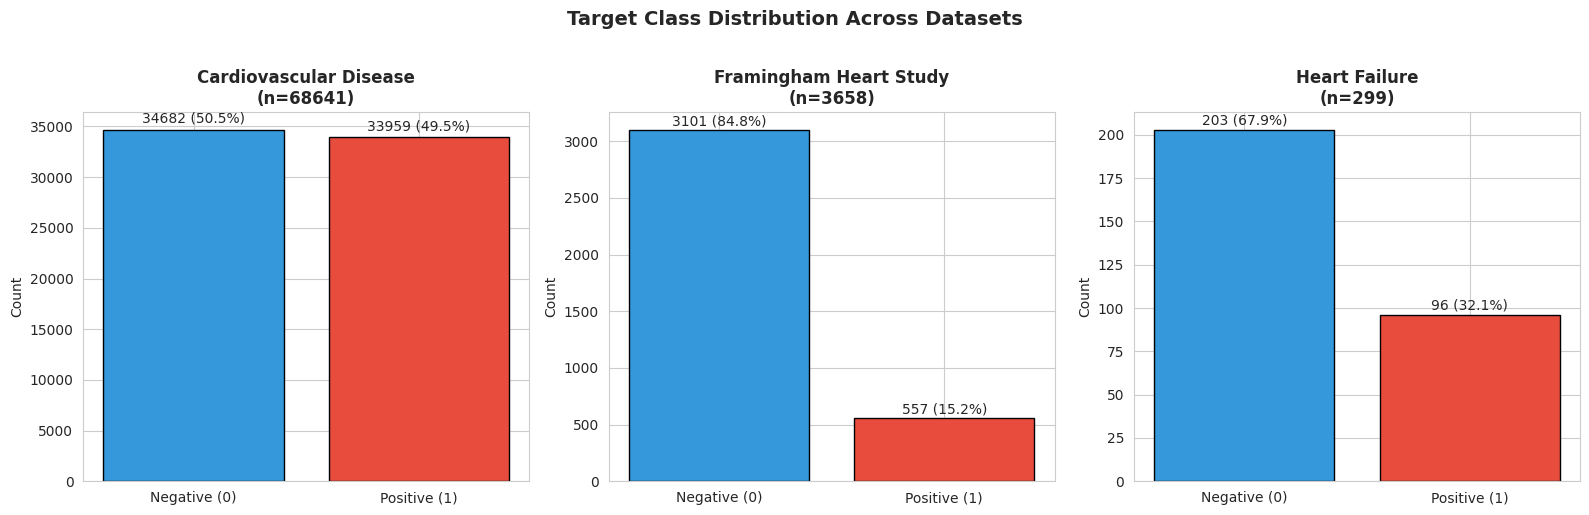

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, d) in zip(axes, [
    ('Cardiovascular Disease', y_cardio),
    ('Framingham Heart Study', y_fram),
    ('Heart Failure', y_hf)
]):
    counts = np.bincount(d)
    ax.bar(['Negative (0)', 'Positive (1)'], counts, color=['#3498db', '#e74c3c'], edgecolor='black')
    ax.set_title(f'{name}\n(n={len(d)})', fontsize=12, fontweight='bold')
    ax.set_ylabel('Count')
    for i, v in enumerate(counts):
        ax.text(i, v + len(d)*0.01, f'{v} ({v/len(d)*100:.1f}%)', ha='center', fontsize=10)

plt.suptitle('Target Class Distribution Across Datasets', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


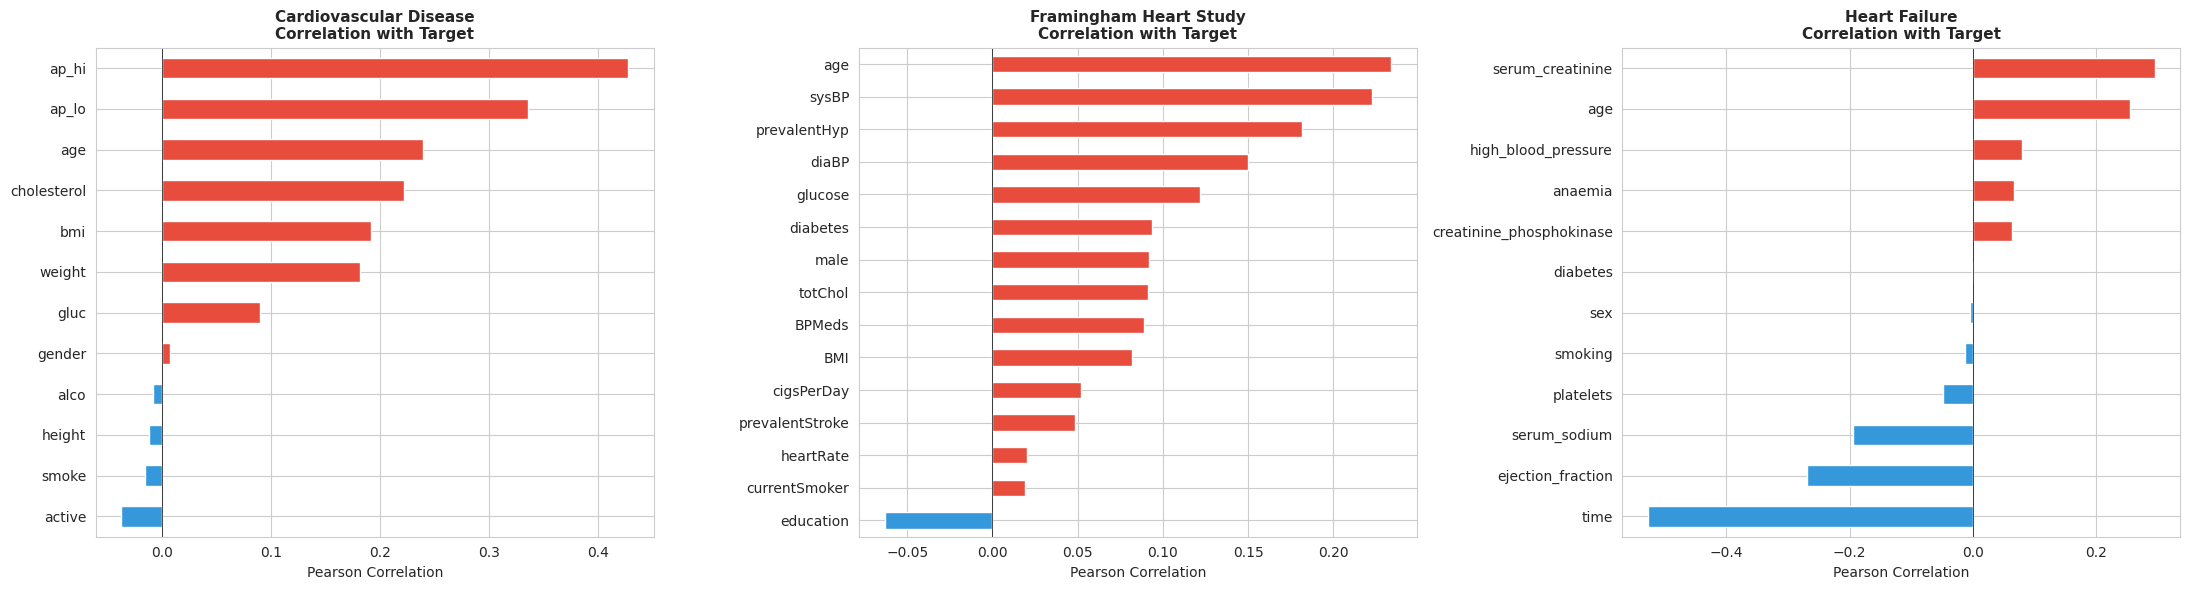

In [ ]:
# Correlation heatmaps for each dataset
fig, axes = plt.subplots(1, 3, figsize=(22, 6))

for ax, (name, df_, target) in zip(axes, [
    ('Cardiovascular Disease', df_cardio, 'cardio'),
    ('Framingham Heart Study', df_fram, 'TenYearCHD'),
    ('Heart Failure', df_hf, 'DEATH_EVENT')
]):
    corr = df_.corr()[target].drop(target).sort_values()
    corr.plot(kind='barh', ax=ax, color=corr.apply(lambda x: '#e74c3c' if x > 0 else '#3498db'))
    ax.set_title(f'{name}\nCorrelation with Target', fontsize=11, fontweight='bold')
    ax.set_xlabel('Pearson Correlation')
    ax.axvline(x=0, color='black', linewidth=0.5)

plt.tight_layout()
plt.show()


## 5. Model Architecture Definitions

### 5.1 Model A — Gaussian Naive Bayes


In [ ]:
def build_model_a():
    """Model A: Gaussian Naive Bayes classifier."""
    return GaussianNB()

Model A: Gaussian Naive Bayes
  - Parametric probabilistic classifier
  - Assumes conditional feature independence given class
  - Class-conditional likelihoods modelled as univariate Gaussians


### 5.2 Model B — Multilayer Perceptron (MLP)

In [ ]:
def build_model_b(input_dim):
    """
    Model B: Feedforward MLP.
    Architecture: input -> Dense(64, ReLU) -> Dropout(0.3) -> Dense(32, ReLU) -> Dropout(0.3) -> Dense(1, Sigmoid)
    """
    model = Sequential([
        Input(shape=(input_dim,)),
        Dense(64, activation='relu'),
        Dropout(0.3),
        Dense(32, activation='relu'),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ])
    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model

# Show architecture
sample_model = build_model_b(10)
sample_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,817 (11.00 KB)

 Trainable params: 2,817 (11.00 KB)

 Non-trainable params: 0 (0.00 B)

### 5.3 Model C — Hybrid GNB-MLP (Proposed Architecture)


In [ ]:
def build_model_c(input_dim):
    """
    Model C: Hybrid GNB-MLP.
    Input dimension = original features + 2 (GNB posterior probabilities).
    Same MLP architecture as Model B but with augmented input.
    """
    augmented_dim = input_dim + 2  # +2 for P(y=0|x) and P(y=1|x)

    model = Sequential([
        Input(shape=(augmented_dim,)),
        Dense(64, activation='relu'),
        Dropout(0.3),
        Dense(32, activation='relu'),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ])
    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model

Model C: Hybrid GNB-MLP
  - Stage 1: GNB produces posterior probabilities
  - Stage 2: Posteriors concatenated with original features
  - Stage 3: Augmented vector fed to MLP (same architecture as Model B)


## 6. Training & Evaluation Pipeline

In [ ]:
def evaluate_model(y_true, y_pred, y_prob):
    """Compute all classification metrics."""
    return {
        'Accuracy':  accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall':    recall_score(y_true, y_pred, zero_division=0),
        'F1-Score':  f1_score(y_true, y_pred, zero_division=0),
        'AUC-ROC':   roc_auc_score(y_true, y_prob)
    }


def train_and_evaluate_all_models(data, dataset_name, epochs=100, batch_size=32):
    """
    Train Models A, B, C on a single dataset and return results.
    """
    X_train = data['X_train']
    X_val   = data['X_val']
    X_test  = data['X_test']
    y_train = data['y_train']
    y_val   = data['y_val']
    y_test  = data['y_test']

    input_dim = X_train.shape[1]
    results = {}

    # ---- MODEL A: Gaussian Naive Bayes ----
    print(f"\n{'='*60}")
    print(f"  {dataset_name} — Model A: Gaussian Naive Bayes")
    print(f"{'='*60}")

    gnb = build_model_a()
    gnb.fit(X_train, y_train)

    y_pred_a = gnb.predict(X_test)
    y_prob_a = gnb.predict_proba(X_test)[:, 1]

    results['Model A (GNB)'] = evaluate_model(y_test, y_pred_a, y_prob_a)
    print(f"Test AUC-ROC: {results['Model A (GNB)']['AUC-ROC']:.4f}")

    # Get GNB posteriors for hybrid model (train, val, test)
    gnb_proba_train = gnb.predict_proba(X_train)
    gnb_proba_val   = gnb.predict_proba(X_val)
    gnb_proba_test  = gnb.predict_proba(X_test)

    # ---- MODEL B: MLP ----
    print(f"\n{'='*60}")
    print(f"  {dataset_name} — Model B: MLP")
    print(f"{'='*60}")

    early_stop = EarlyStopping(
        monitor='val_loss', patience=10, restore_best_weights=True, verbose=0
    )

    model_b = build_model_b(input_dim)
    history_b = model_b.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=epochs, batch_size=batch_size,
        callbacks=[early_stop],
        verbose=0
    )

    y_prob_b = model_b.predict(X_test, verbose=0).flatten()
    y_pred_b = (y_prob_b >= 0.5).astype(int)

    results['Model B (MLP)'] = evaluate_model(y_test, y_pred_b, y_prob_b)
    print(f"Test AUC-ROC: {results['Model B (MLP)']['AUC-ROC']:.4f}")
    print(f"Stopped at epoch: {len(history_b.history['loss'])}")

    # ---- MODEL C: Hybrid GNB-MLP ----
    print(f"\n{'='*60}")
    print(f"  {dataset_name} — Model C: Hybrid GNB-MLP")
    print(f"{'='*60}")

    # Augment features with GNB posteriors
    X_train_aug = np.hstack([X_train, gnb_proba_train])
    X_val_aug   = np.hstack([X_val, gnb_proba_val])
    X_test_aug  = np.hstack([X_test, gnb_proba_test])

    print(f"Augmented feature dim: {X_train_aug.shape[1]} (original {input_dim} + 2 GNB posteriors)")

    early_stop_c = EarlyStopping(
        monitor='val_loss', patience=10, restore_best_weights=True, verbose=0
    )

    model_c = build_model_c(input_dim)
    history_c = model_c.fit(
        X_train_aug, y_train,
        validation_data=(X_val_aug, y_val),
        epochs=epochs, batch_size=batch_size,
        callbacks=[early_stop_c],
        verbose=0
    )

    y_prob_c = model_c.predict(X_test_aug, verbose=0).flatten()
    y_pred_c = (y_prob_c >= 0.5).astype(int)

    results['Model C (Hybrid)'] = evaluate_model(y_test, y_pred_c, y_prob_c)
    print(f"Test AUC-ROC: {results['Model C (Hybrid)']['AUC-ROC']:.4f}")
    print(f"Stopped at epoch: {len(history_c.history['loss'])}")

    return {
        'results': results,
        'models': {'gnb': gnb, 'mlp': model_b, 'hybrid': model_c},
        'histories': {'mlp': history_b, 'hybrid': history_c},
        'predictions': {
            'Model A (GNB)':     {'y_pred': y_pred_a, 'y_prob': y_prob_a},
            'Model B (MLP)':     {'y_pred': y_pred_b, 'y_prob': y_prob_b},
            'Model C (Hybrid)':  {'y_pred': y_pred_c, 'y_prob': y_prob_c},
        },
        'y_test': y_test,
        'gnb_probas': {
            'train': gnb_proba_train, 'val': gnb_proba_val, 'test': gnb_proba_test
        }
    }

print("Training & evaluation pipeline defined.")


Training & evaluation pipeline defined.


### 6.1 Run on All Datasets

In [ ]:
all_results = {}

for name, data in datasets.items():
    all_results[name] = train_and_evaluate_all_models(
        data, name, epochs=100, batch_size=32
    )

print("\n" + "="*60)
print("  ALL TRAINING COMPLETE")
print("="*60)



  Cardiovascular Disease — Model A: Gaussian Naive Bayes
Test AUC-ROC: 0.7663

  Cardiovascular Disease — Model B: MLP
Test AUC-ROC: 0.7920
Stopped at epoch: 48

  Cardiovascular Disease — Model C: Hybrid GNB-MLP
Augmented feature dim: 14 (original 12 + 2 GNB posteriors)
Test AUC-ROC: 0.7924
Stopped at epoch: 40

  Framingham Heart Study — Model A: Gaussian Naive Bayes
Test AUC-ROC: 0.6757

  Framingham Heart Study — Model B: MLP
Test AUC-ROC: 0.7174
Stopped at epoch: 25

  Framingham Heart Study — Model C: Hybrid GNB-MLP
Augmented feature dim: 17 (original 15 + 2 GNB posteriors)
Test AUC-ROC: 0.6890
Stopped at epoch: 13

  Heart Failure Clinical Records — Model A: Gaussian Naive Bayes
Test AUC-ROC: 0.7972

  Heart Failure Clinical Records — Model B: MLP
Test AUC-ROC: 0.8203
Stopped at epoch: 55

  Heart Failure Clinical Records — Model C: Hybrid GNB-MLP
Augmented feature dim: 14 (original 12 + 2 GNB posteriors)


Test AUC-ROC: 0.7949
Stopped at epoch: 73

  ALL TRAINING COMPLETE


## 7. Results & Analysis

### 7.1 Performance Metrics Summary

In [ ]:
# Build summary table
rows = []
for ds_name, res in all_results.items():
    for model_name, metrics in res['results'].items():
        row = {'Dataset': ds_name, 'Model': model_name}
        row.update(metrics)
        rows.append(row)

results_df = pd.DataFrame(rows)
results_df = results_df.round(4)

# Display per dataset
for ds in results_df['Dataset'].unique():
    print(f"\n{'='*70}")
    print(f"  {ds}")
    print(f"{'='*70}")
    subset = results_df[results_df['Dataset'] == ds].set_index('Model')
    print(subset[['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC']].to_string())



  Cardiovascular Disease
                  Accuracy  Precision  Recall  F1-Score  AUC-ROC
Model                                                           
Model A (GNB)       0.7033     0.7462  0.6066    0.6692   0.7663
Model B (MLP)       0.7233     0.7374  0.6845    0.7100   0.7920
Model C (Hybrid)    0.7249     0.7405  0.6834    0.7108   0.7924

  Framingham Heart Study
                  Accuracy  Precision  Recall  F1-Score  AUC-ROC
Model                                                           
Model A (GNB)       0.8251      0.375  0.2143    0.2727   0.6757
Model B (MLP)       0.8470      0.500  0.0476    0.0870   0.7174
Model C (Hybrid)    0.8470      0.500  0.0357    0.0667   0.6890

  Heart Failure Clinical Records
                  Accuracy  Precision  Recall  F1-Score  AUC-ROC
Model                                                           
Model A (GNB)       0.7111     0.5556  0.3571    0.4348   0.7972
Model B (MLP)       0.6889     0.5000  0.5000    0.5000   0.8203
Mode

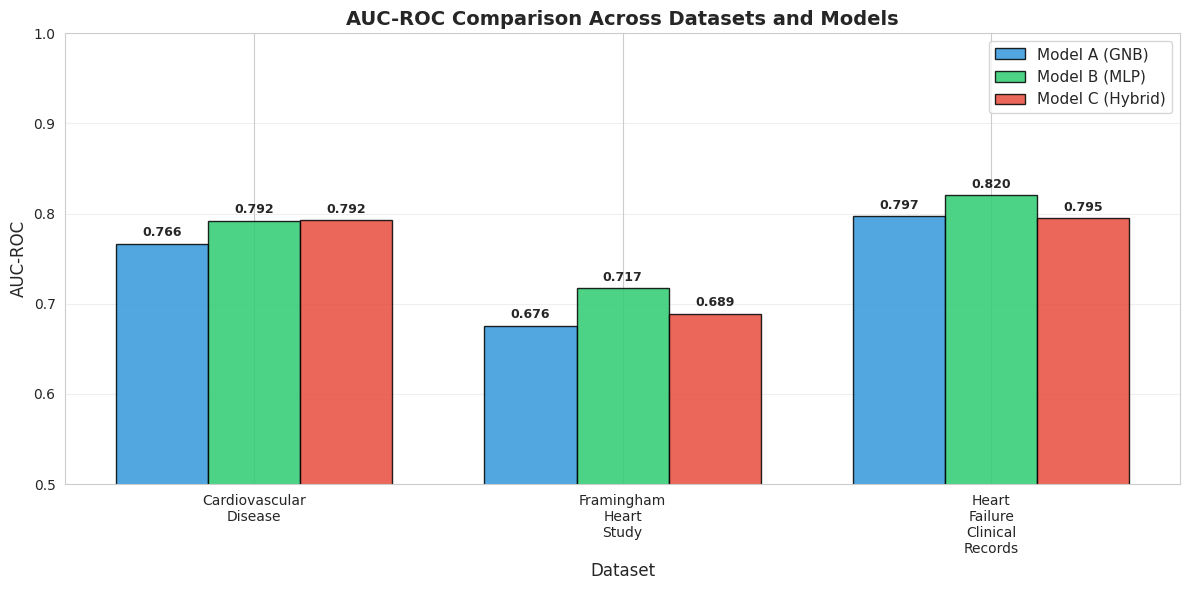

In [ ]:
# Visual comparison: AUC-ROC across datasets and models
fig, ax = plt.subplots(figsize=(12, 6))

datasets_names = list(all_results.keys())
models_names = ['Model A (GNB)', 'Model B (MLP)', 'Model C (Hybrid)']
colors = ['#3498db', '#2ecc71', '#e74c3c']
x = np.arange(len(datasets_names))
width = 0.25

for i, (model, color) in enumerate(zip(models_names, colors)):
    aucs = [all_results[ds]['results'][model]['AUC-ROC'] for ds in datasets_names]
    bars = ax.bar(x + i * width, aucs, width, label=model, color=color, edgecolor='black', alpha=0.85)
    for bar, auc in zip(bars, aucs):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f'{auc:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

ax.set_xlabel('Dataset', fontsize=12)
ax.set_ylabel('AUC-ROC', fontsize=12)
ax.set_title('AUC-ROC Comparison Across Datasets and Models', fontsize=14, fontweight='bold')
ax.set_xticks(x + width)
ax.set_xticklabels([n.replace(' ', '\n') for n in datasets_names], fontsize=10)
ax.legend(fontsize=11)
ax.set_ylim(0.5, 1.0)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


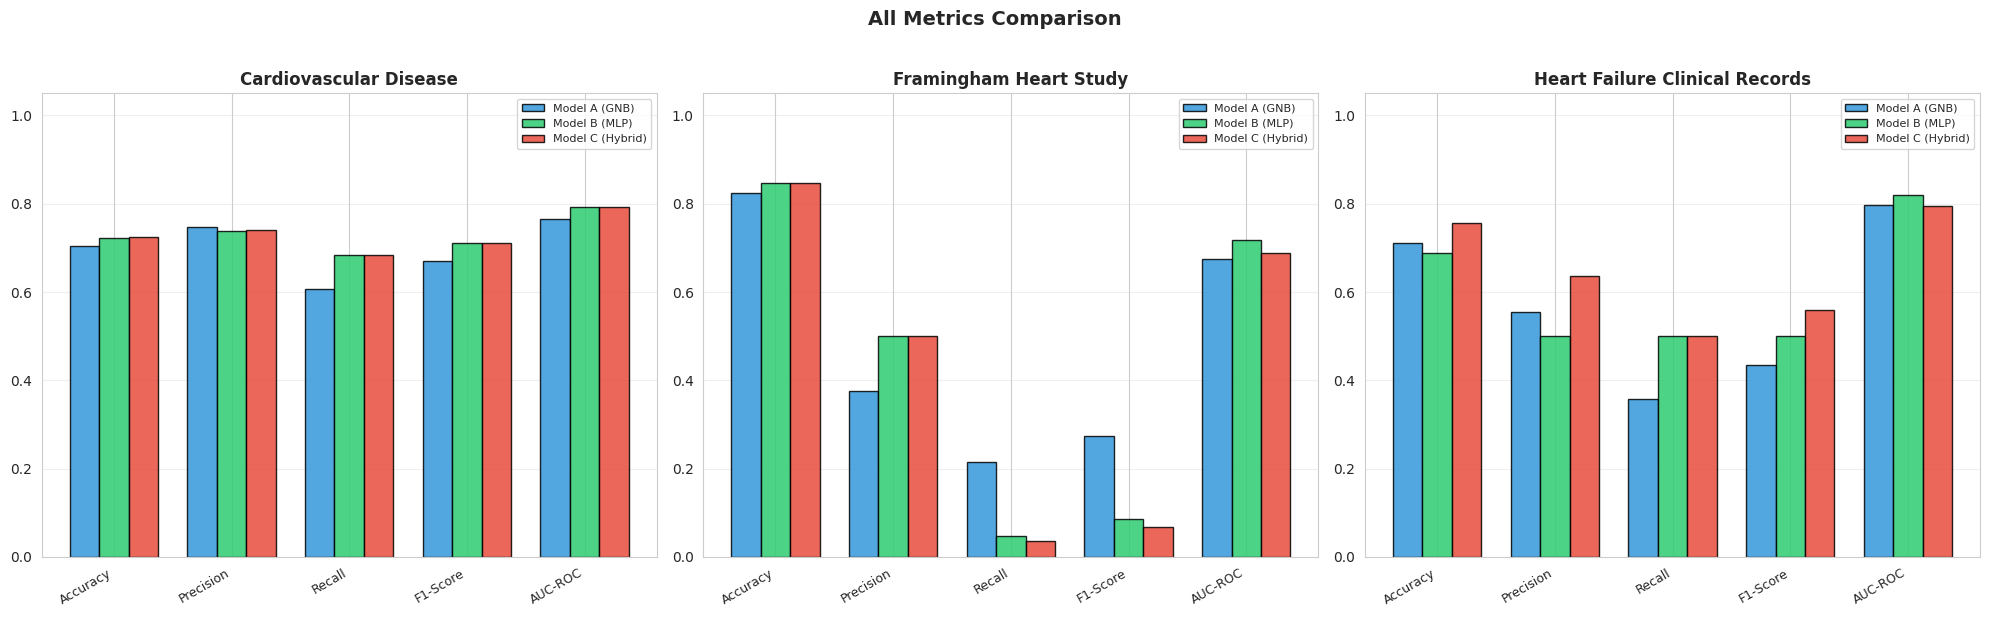

In [ ]:
# All metrics comparison
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
metric_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC']

for ax, ds_name in zip(axes, datasets_names):
    res = all_results[ds_name]['results']
    x_pos = np.arange(len(metric_names))

    for i, (model, color) in enumerate(zip(models_names, colors)):
        vals = [res[model][m] for m in metric_names]
        ax.bar(x_pos + i * 0.25, vals, 0.25, label=model, color=color, alpha=0.85, edgecolor='black')

    ax.set_title(ds_name, fontsize=12, fontweight='bold')
    ax.set_xticks(x_pos + 0.25)
    ax.set_xticklabels(metric_names, rotation=30, ha='right', fontsize=9)
    ax.set_ylim(0, 1.05)
    ax.legend(fontsize=8)
    ax.grid(axis='y', alpha=0.3)

plt.suptitle('All Metrics Comparison', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


### 7.2 Confusion Matrix Analysis

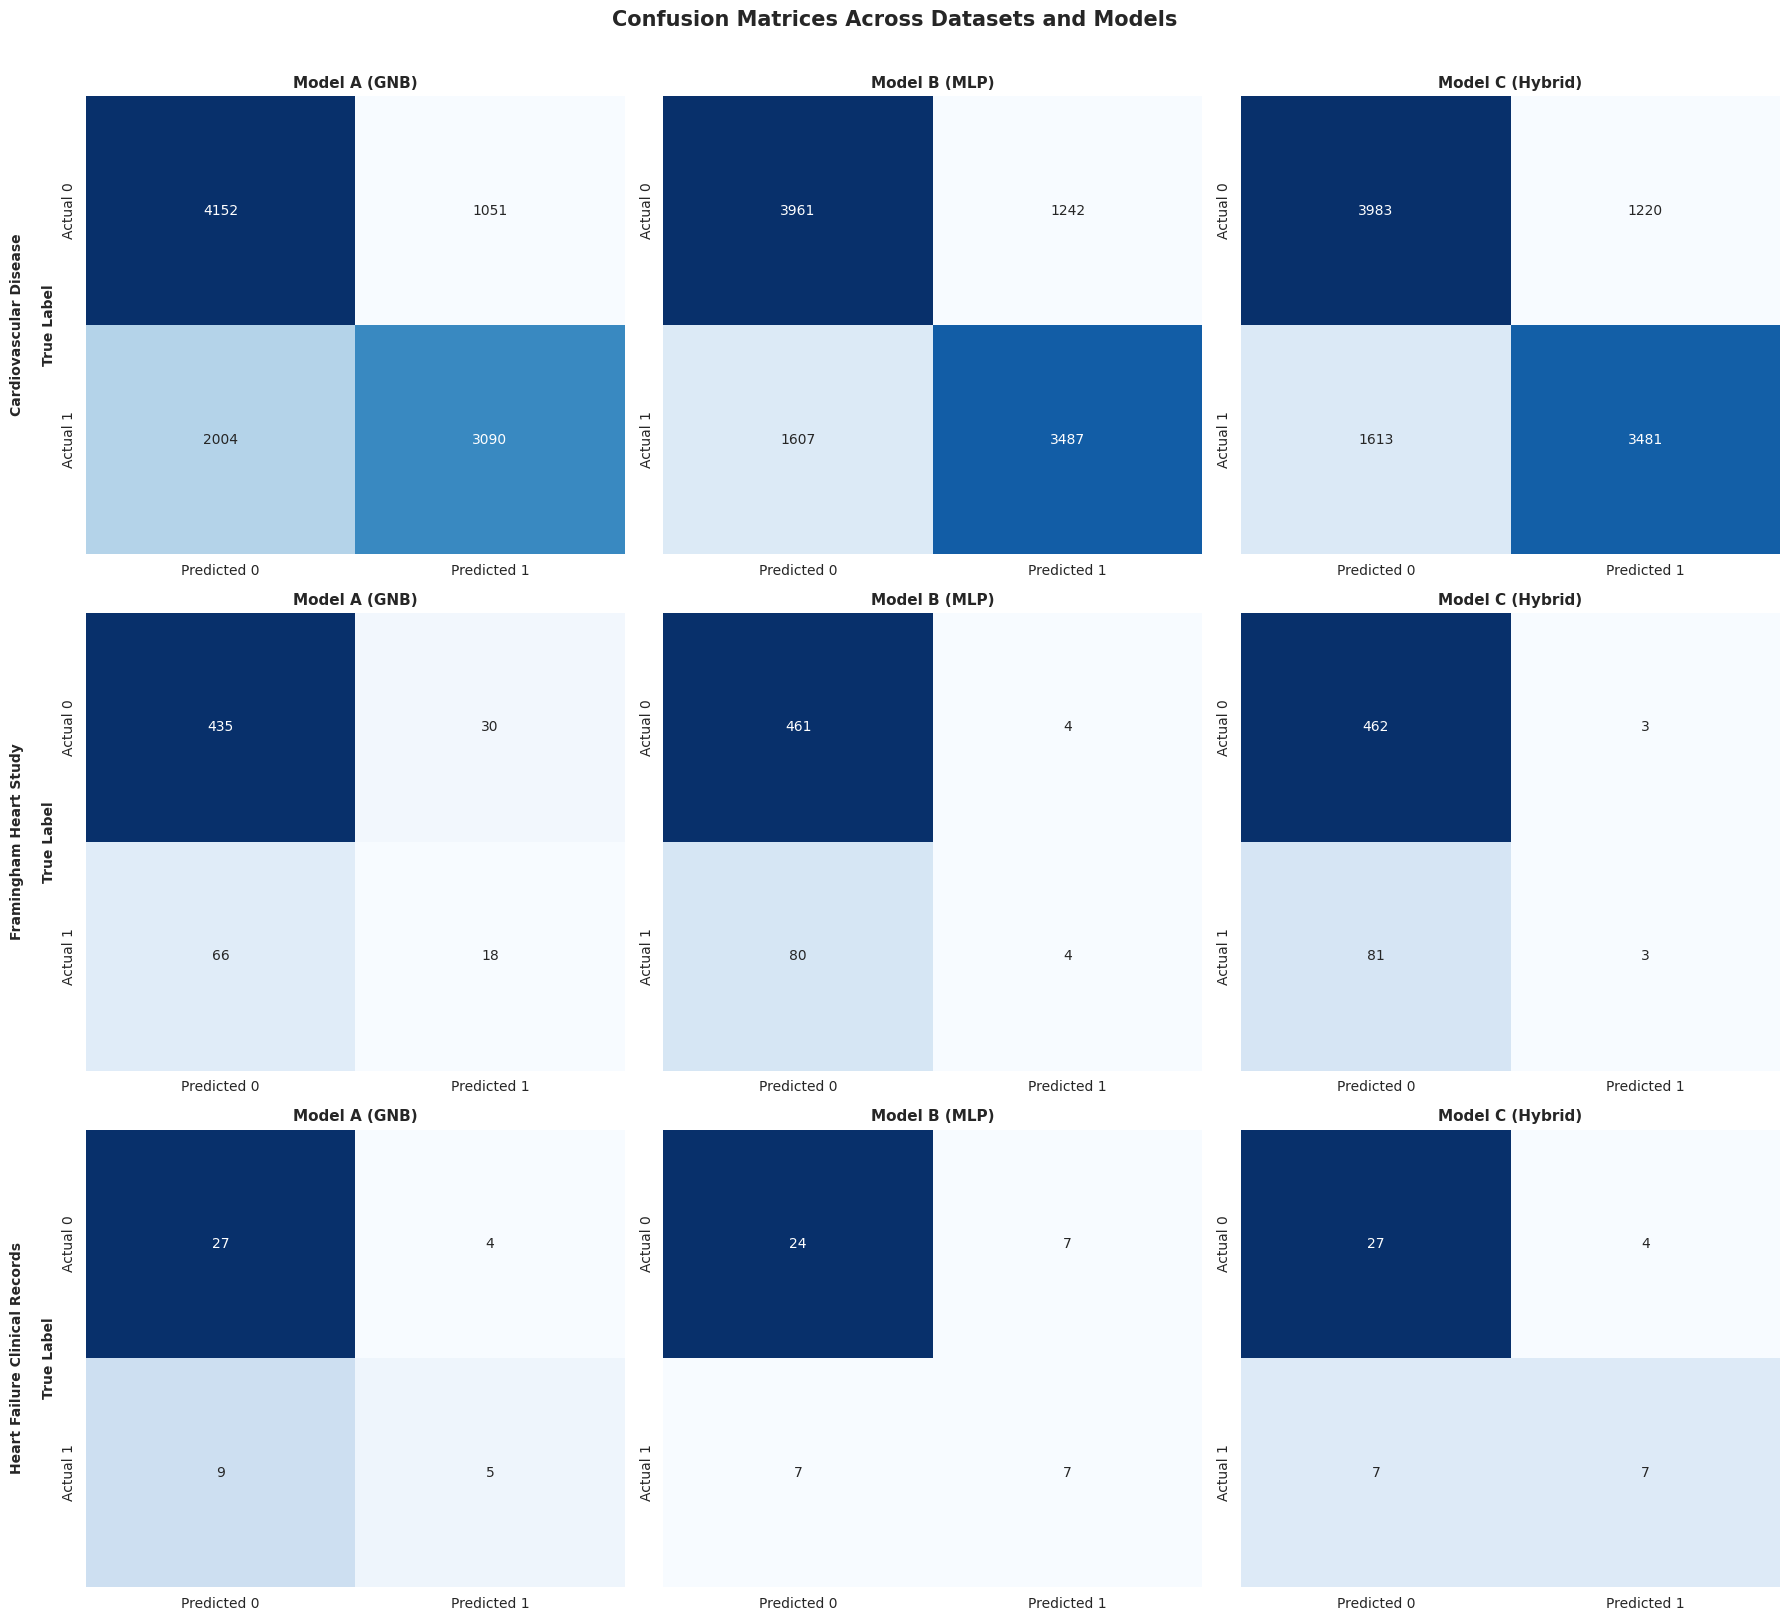

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(18, 16))

for row, ds_name in enumerate(datasets_names):
    y_test = all_results[ds_name]['y_test']
    for col, model_name in enumerate(models_names):
        y_pred = all_results[ds_name]['predictions'][model_name]['y_pred']
        cm = confusion_matrix(y_test, y_pred)

        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[row][col],
                    xticklabels=['Predicted 0', 'Predicted 1'],
                    yticklabels=['Actual 0', 'Actual 1'],
                    cbar=False)
        axes[row][col].set_title(f'{model_name}', fontsize=11, fontweight='bold')

        if col == 0:
            axes[row][col].set_ylabel(f'{ds_name}\n\nTrue Label', fontsize=10, fontweight='bold')

plt.suptitle('Confusion Matrices Across Datasets and Models', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


### 7.3 ROC Curve Analysis

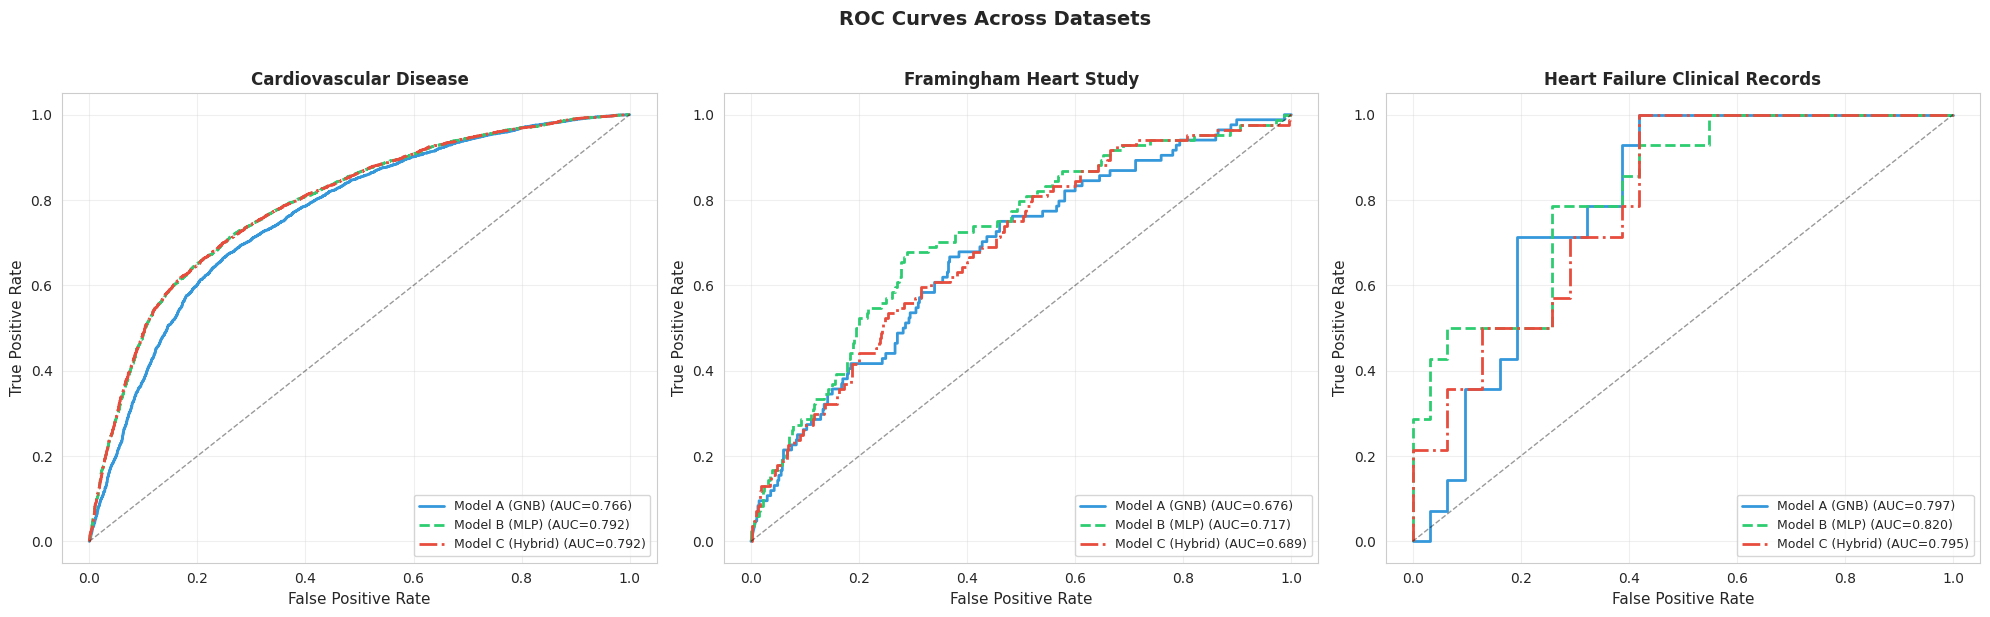

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for ax, ds_name in zip(axes, datasets_names):
    y_test = all_results[ds_name]['y_test']

    for model_name, color, ls in zip(models_names, colors, ['-', '--', '-.']):
        y_prob = all_results[ds_name]['predictions'][model_name]['y_prob']
        fpr, tpr, _ = roc_curve(y_test, y_prob)
        auc = roc_auc_score(y_test, y_prob)
        ax.plot(fpr, tpr, color=color, linestyle=ls, linewidth=2,
                label=f'{model_name} (AUC={auc:.3f})')

    ax.plot([0, 1], [0, 1], 'k--', alpha=0.4, linewidth=1)
    ax.set_xlabel('False Positive Rate', fontsize=11)
    ax.set_ylabel('True Positive Rate', fontsize=11)
    ax.set_title(f'{ds_name}', fontsize=12, fontweight='bold')
    ax.legend(loc='lower right', fontsize=9)
    ax.grid(alpha=0.3)

plt.suptitle('ROC Curves Across Datasets', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


### 7.4 Training History (Loss & Accuracy)

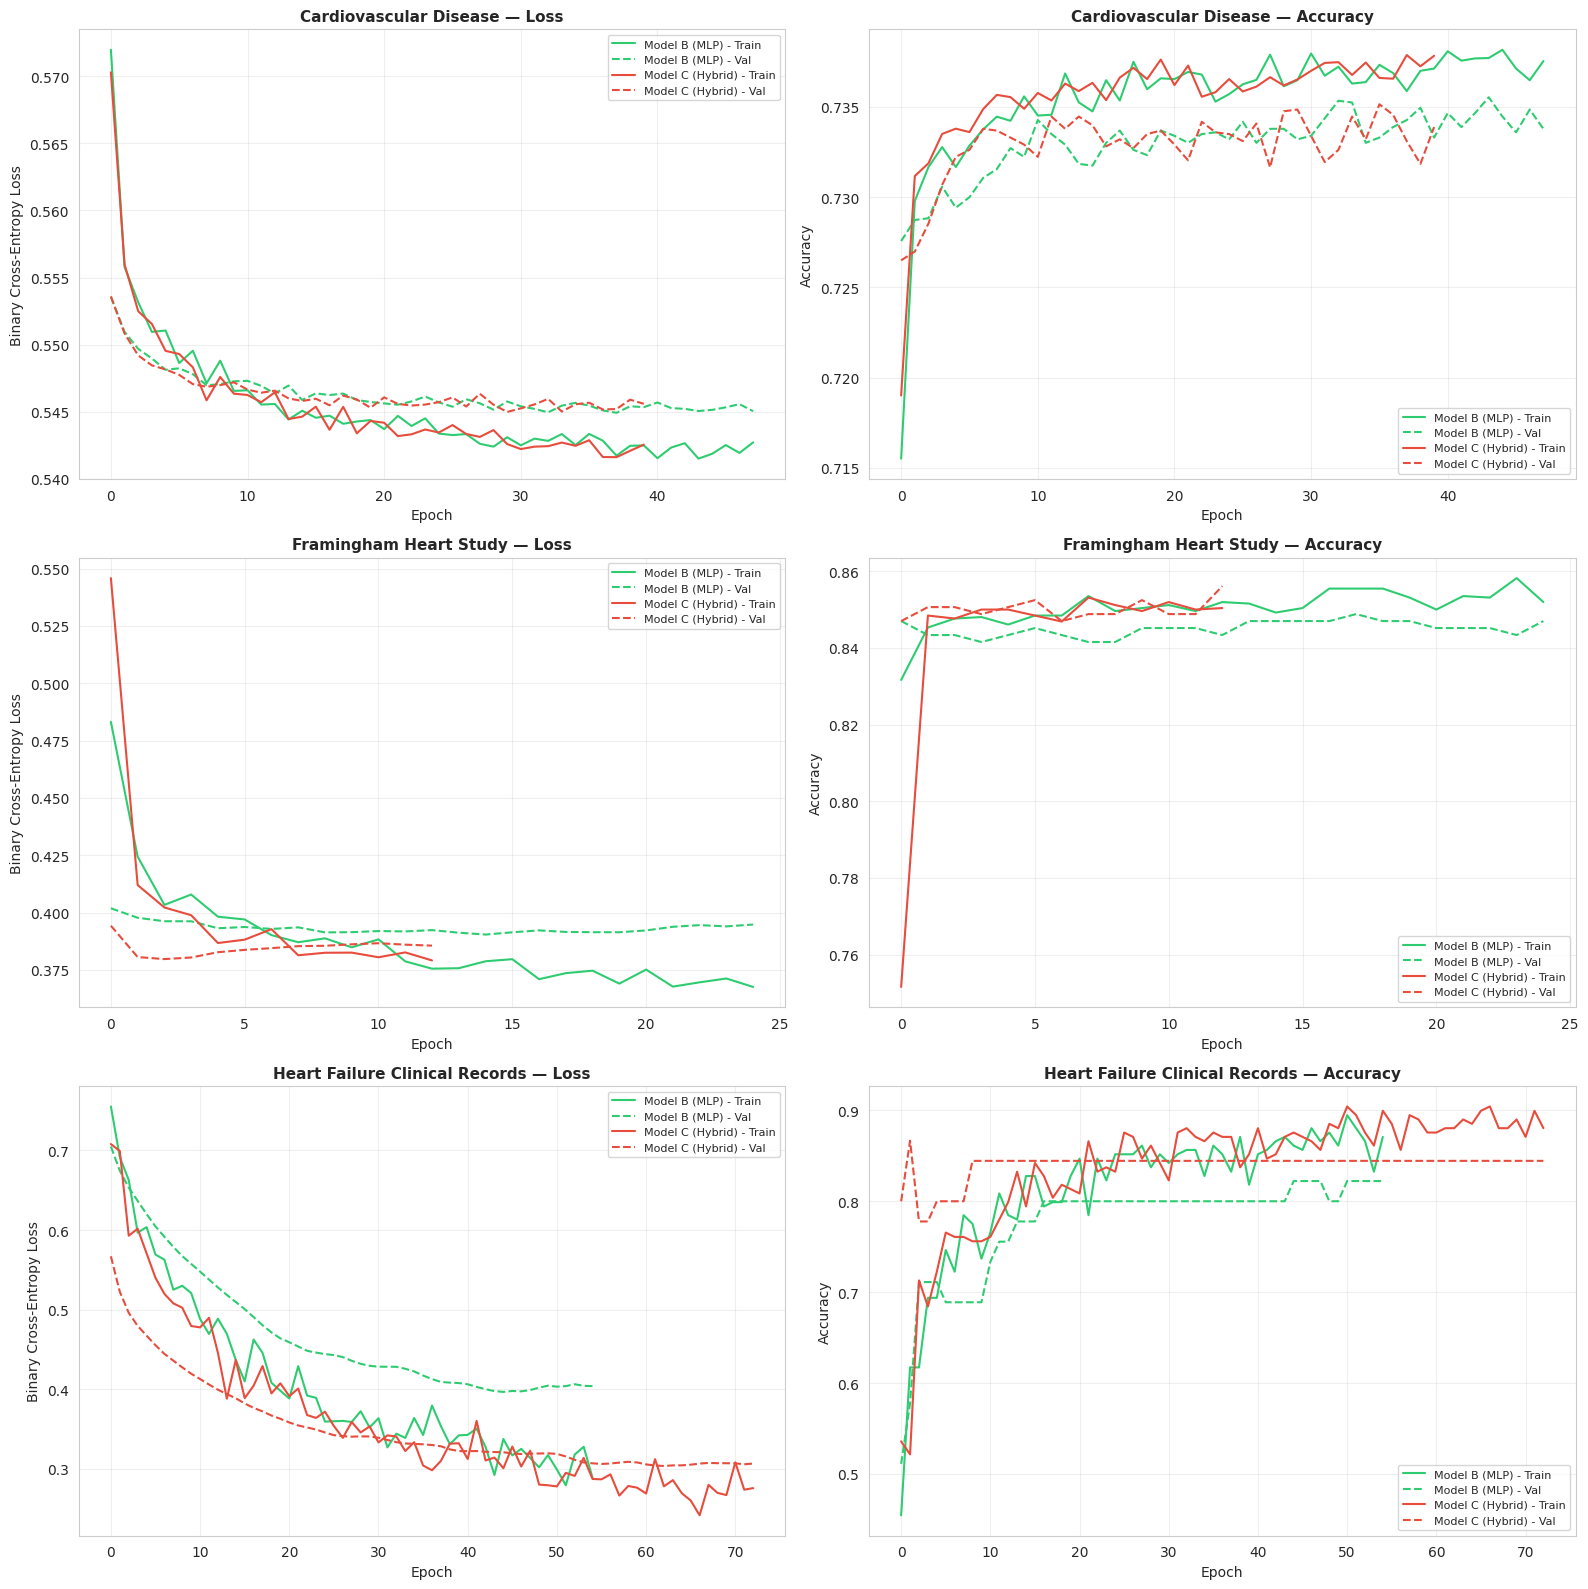

In [ ]:
fig, axes = plt.subplots(3, 2, figsize=(16, 16))

for row, ds_name in enumerate(datasets_names):
    histories = all_results[ds_name]['histories']

    for model_key, label, color in [('mlp', 'Model B (MLP)', '#2ecc71'),
                                      ('hybrid', 'Model C (Hybrid)', '#e74c3c')]:
        h = histories[model_key].history

        # Loss
        axes[row][0].plot(h['loss'], label=f'{label} - Train', color=color, linewidth=1.5)
        axes[row][0].plot(h['val_loss'], label=f'{label} - Val', color=color,
                         linestyle='--', linewidth=1.5)
        axes[row][0].set_title(f'{ds_name} — Loss', fontsize=11, fontweight='bold')
        axes[row][0].set_xlabel('Epoch')
        axes[row][0].set_ylabel('Binary Cross-Entropy Loss')
        axes[row][0].legend(fontsize=8)
        axes[row][0].grid(alpha=0.3)

        # Accuracy
        axes[row][1].plot(h['accuracy'], label=f'{label} - Train', color=color, linewidth=1.5)
        axes[row][1].plot(h['val_accuracy'], label=f'{label} - Val', color=color,
                         linestyle='--', linewidth=1.5)
        axes[row][1].set_title(f'{ds_name} — Accuracy', fontsize=11, fontweight='bold')
        axes[row][1].set_xlabel('Epoch')
        axes[row][1].set_ylabel('Accuracy')
        axes[row][1].legend(fontsize=8)
        axes[row][1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


## 8. Detailed Classification Reports

In [ ]:
for ds_name in datasets_names:
    print(f"\n{'='*70}")
    print(f"  {ds_name}")
    print(f"{'='*70}")
    y_test = all_results[ds_name]['y_test']

    for model_name in models_names:
        y_pred = all_results[ds_name]['predictions'][model_name]['y_pred']
        print(f"\n--- {model_name} ---")
        print(classification_report(y_test, y_pred, target_names=['No CVD', 'CVD'], digits=4))



  Cardiovascular Disease

--- Model A (GNB) ---
              precision    recall  f1-score   support

      No CVD     0.6745    0.7980    0.7311      5203
         CVD     0.7462    0.6066    0.6692      5094

    accuracy                         0.7033     10297
   macro avg     0.7103    0.7023    0.7001     10297
weighted avg     0.7100    0.7033    0.7004     10297


--- Model B (MLP) ---
              precision    recall  f1-score   support

      No CVD     0.7114    0.7613    0.7355      5203
         CVD     0.7374    0.6845    0.7100      5094

    accuracy                         0.7233     10297
   macro avg     0.7244    0.7229    0.7227     10297
weighted avg     0.7242    0.7233    0.7229     10297


--- Model C (Hybrid) ---
              precision    recall  f1-score   support

      No CVD     0.7118    0.7655    0.7377      5203
         CVD     0.7405    0.6834    0.7108      5094

    accuracy                         0.7249     10297
   macro avg     0.7261    0.7

## 9. Results Table

In [ ]:
# Final combined table
print("\nFull Results Table:\n")
display_df = results_df.copy()
display_df.columns = ['Dataset', 'Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC']
print(display_df.to_string(index=False))



Full Results Table:

                       Dataset            Model  Accuracy  Precision  Recall  F1-Score  AUC-ROC
        Cardiovascular Disease    Model A (GNB)    0.7033     0.7462  0.6066    0.6692   0.7663
        Cardiovascular Disease    Model B (MLP)    0.7233     0.7374  0.6845    0.7100   0.7920
        Cardiovascular Disease Model C (Hybrid)    0.7249     0.7405  0.6834    0.7108   0.7924
        Framingham Heart Study    Model A (GNB)    0.8251     0.3750  0.2143    0.2727   0.6757
        Framingham Heart Study    Model B (MLP)    0.8470     0.5000  0.0476    0.0870   0.7174
        Framingham Heart Study Model C (Hybrid)    0.8470     0.5000  0.0357    0.0667   0.6890
Heart Failure Clinical Records    Model A (GNB)    0.7111     0.5556  0.3571    0.4348   0.7972
Heart Failure Clinical Records    Model B (MLP)    0.6889     0.5000  0.5000    0.5000   0.8203
Heart Failure Clinical Records Model C (Hybrid)    0.7556     0.6364  0.5000    0.5600   0.7949
